# **Índice del Notebook**

---

## **1. Importación de Librerías**<br>
## **2. Carga de la Base de Datos**<br>
## **3. Declaración de las Variables y Parámetros a Utilizar**<br>
## **4. Análisis Exploratorio de la Muestra**

---

## **5. Hipótesis 1**<br>
### 5.1. Formulación<br>
### 5.2. Diseño de la Prueba<br>
### 5.3. Resultados<br>
### 5.4. Conclusiones

---
## **6. Hipótesis 2**<br>
### 6.1. Formulación<br>
### 6.2. Diseño de la Prueba<br>
### 6.3. Resultados<br>
### 6.4. Conclusiones
---
## **7. Hipótesis 3**<br>
### 7.1. Formulación<br>
### 7.2. Diseño de la Prueba<br>
### 7.3. Resultados<br>
### 7.4. Conclusiones

## **1. Importación de Librerías**

In [1]:
import io
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import folium
from folium.plugins import HeatMap, MarkerCluster
import plotly.express as px
from IPython.display import display
import re

## **2. Carga de la Base de Datos**

In [2]:
uploaded = files.upload()

def read_file_robust(name, file_bytes):
    if name.lower().endswith('.xlsx'):
        # Para archivos Excel
        return pd.read_excel(io.BytesIO(file_bytes))

    # Para archivos CSV, probando distintas codificaciones
    for enc in ["utf-8-sig", "utf-8", "latin1"]:
        try:
            return pd.read_csv(io.BytesIO(file_bytes), encoding=enc, low_memory=False)
        except UnicodeDecodeError:
            pass
    raise ValueError(f"Could not decode CSV file: {name}")

# Cargamos tanto archivos CSV como Excel
loaded = {
    name: read_file_robust(name, content)
    for name, content in uploaded.items()
    if name.lower().endswith((".csv", ".xlsx"))
}

if len(loaded) < 2:
    raise ValueError("Please upload both files (CSV or Excel).")

obs_name, survey_name = None, None
for name, df in loaded.items():
    cols = set(df.columns)
    if {"ResponseId", "GPS_Latitude", "GPS_Longitude"}.issubset(cols):
        obs_name = name
    if {"ResponseId", "ObservationID"}.issubset(cols):
        survey_name = name

if obs_name is None or survey_name is None:
    raise ValueError("Could not automatically distinguish the observation and survey files.")

obs_raw = loaded[obs_name].copy()
survey_raw = loaded[survey_name].copy()

# Quitamos la fila con el texto de las preguntas que trae el export de Qualtrics (los registros reales tienen ResponseId que empieza con "R_")
obs_raw = obs_raw[obs_raw["ResponseId"].astype(str).str.startswith("R_")].copy()
survey_raw = survey_raw[survey_raw["ResponseId"].astype(str).str.startswith("R_")].copy()

# Validación de Calidad: Coordenadas dentro de Argentina
lat = pd.to_numeric(obs_raw["GPS_Latitude"], errors="coerce")
lon = pd.to_numeric(obs_raw["GPS_Longitude"], errors="coerce")

# Bounding box territorial de Argentina
valid_argentina = (
    (lat >= -55.0) & (lat <= -21.0) &
    (lon >= -73.0) & (lon <= -53.0)
)

dropped_obs = len(obs_raw) - valid_argentina.sum()
obs_raw = obs_raw[valid_argentina].copy()

if dropped_obs > 0:
    print(f"[Filtro Geográfico] Se descartaron {dropped_obs} observaciones fuera de Argentina.")

print(f"Observations: {obs_name} | {obs_raw.shape}")
print(f"Courier survey: {survey_name} | {survey_raw.shape}")

Saving ILI_Argentina_courier_survey_2026-10-31.xlsx to ILI_Argentina_courier_survey_2026-10-31.xlsx
Saving ILI_Argentina_observations_2026-10-31.xlsx to ILI_Argentina_observations_2026-10-31.xlsx
[Filtro Geográfico] Se descartaron 3 observaciones fuera de Argentina.
Observations: ILI_Argentina_observations_2026-10-31.xlsx | (1760, 72)
Courier survey: ILI_Argentina_courier_survey_2026-10-31.xlsx | (151, 56)


## **3. Declaración de las Variables y Parámetros a Utilizar**

In [3]:
# DECLARACIÓN DE VARIABLES

# 1. Copias de trabajo limpias desde los dataframes crudos
df_obs = obs_raw.copy()
df_survey = survey_raw.copy()

# 2. Renombrado y selección de variables clave para las Observaciones (df_obs)
renombres_obs = {
    'Q8': 'tipo_vehiculo',
    'Q28': 'lugar_inactividad',
    'Q12': 'estacionamiento_legal',
    'Q23': 'actividad',
    'GPS_Latitude': 'latitud',
    'GPS_Longitude': 'longitud'
}

# 3. Renombrado y selección de variables clave para la Encuesta a Repartidores (df_survey)
renombres_survey = {
    'Q5_HORAS_IMPRODUCTIV_1': 'horas_espera',
    'Q14_CONDICIONES': 'condiciones_adversas_survey'
}

df_obs = df_obs.rename(columns=renombres_obs)
df_survey = df_survey.rename(columns=renombres_survey)

print("Mostramos las dimensiones de cada archivo con el formato: (filas, columnas)")
print("Las filas representan la cantidad de registros y las columnas la cantidad de variables")
print(f"Dimensiones de df_obs listas para análisis: {df_obs.shape}")
print(f"Dimensiones de df_survey listas para análisis: {df_survey.shape}")

# VERIFICACIÓN DE DUPLICADOS
# Un registro repetido contaría dos veces la misma observación (o al mismo repartidor).
dup_obs = int(df_obs["ResponseId"].duplicated().sum())
dup_survey = int(df_survey["ResponseId"].duplicated().sum())

ids_vinculo = df_survey["ObservationID"].astype(str)
ids_vinculo = ids_vinculo[ids_vinculo.str.startswith("R_")]
dup_vinculo = int(ids_vinculo.duplicated().sum())

repetidos = ids_vinculo[ids_vinculo.duplicated(keep=False)]
repetidos_vinculados = int(repetidos.isin(set(df_obs["ResponseId"].astype(str))).sum())

print("--- VERIFICACIÓN DE DUPLICADOS ---")
print(f"Observaciones con ResponseId repetido: {dup_obs}")
print(f"Encuestas con ResponseId repetido: {dup_survey}")
print(f"Encuestas cuyo ObservationID ya aparece en otra encuesta: {dup_vinculo}")
print(f"  (hay {len(repetidos)} encuestas que comparten ObservationID; {repetidos_vinculados} de ellas se vinculan con una observación de campo)")
print("-> No hay observaciones duplicadas." if dup_obs == 0 else "-> ATENCIÓN: hay observaciones duplicadas, hay que revisarlas.")
print("-> Donde se cruzan las bases (hipótesis 3) se conserva un solo registro por ObservationID.")

# Declaro los parámetros de Alpha a utilizar, es decir, el nivel de significancia
ALPHA = 0.05
ALPHA_LAXO = 0.10
ALPHA_ROBUSTO = 0.01

# Todas las hipótesis tendrán un nivel de error principal del 5%, sin embargo, también vamos a usar uno más laxo y uno más robusto, exponiendo los resultados y conclusiones con estos también.

# Función para dar formato al p-valor (se usa en todas las hipótesis)
def fmt_p(p):
    """Formato para informar el p-valor."""
    return "p < 0,001" if p < 0.001 else "p = " + f"{p:.3f}".replace(".", ",")

Mostramos las dimensiones de cada archivo con el formato: (filas, columnas)
Las filas representan la cantidad de registros y las columnas la cantidad de variables
Dimensiones de df_obs listas para análisis: (1760, 72)
Dimensiones de df_survey listas para análisis: (151, 56)
--- VERIFICACIÓN DE DUPLICADOS ---
Observaciones con ResponseId repetido: 0
Encuestas con ResponseId repetido: 0
Encuestas cuyo ObservationID ya aparece en otra encuesta: 25
  (hay 34 encuestas que comparten ObservationID; 8 de ellas se vinculan con una observación de campo)
-> No hay observaciones duplicadas.
-> Donde se cruzan las bases (hipótesis 3) se conserva un solo registro por ObservationID.


## **4. Análisis Exploratorio de la Muestra**

### 4.1. Resumen del Tamaño de la Muestra

In [4]:
# Resumen general del tamaño de la muestra final
total_obs = len(df_obs)
total_survey = len(df_survey)

print("=" * 50)
print(" RESUMEN GENERAL DE LA MUESTRA")
print("=" * 50)
print(f"Total de observaciones de campo válidas (df_obs): {total_obs:,}")
print(f"Total de encuestas a repartidores procesadas (df_survey): {total_survey:,}")
print("=" * 50)

 RESUMEN GENERAL DE LA MUESTRA
Total de observaciones de campo válidas (df_obs): 1,760
Total de encuestas a repartidores procesadas (df_survey): 151


### 4.2. Mapa de Calor de las Observaciones

In [5]:
# Preparamos las coordenadas
map_df = df_obs[["latitud", "longitud"]].copy()

map_df["latitud"] = pd.to_numeric(
    map_df["latitud"], errors="coerce"
)

map_df["longitud"] = pd.to_numeric(
    map_df["longitud"], errors="coerce"
)

map_df = map_df.dropna(subset=["latitud", "longitud"])

if map_df.empty:
    print("No valid geographic coordinates were found.")

else:
    center = [-34.75, -58.25]

    # Creamos el mapa
    m = folium.Map(
        location=center,
        zoom_start=10,
        tiles="https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png?key=YOUR-CARTO-KEY",
        attr="© OpenStreetMap contributors © CARTO",
        control_scale=True
    )

    # Ajustamos el encuadre
    m.fit_bounds([
        [-35.15, -58.65],
        [-34.45, -57.70]
    ])

    # Agregamos el mapa de calor
    HeatMap(
        data=map_df[["latitud", "longitud"]].values.tolist(),
        radius=12,
        blur=15,
        min_opacity=0.3
    ).add_to(m)

    # Mostramos la cantidad de observaciones
    print(f"Observations mapped: {len(map_df)}")

    # Mostramos el mapa
    # display(m)

Observations mapped: 1760


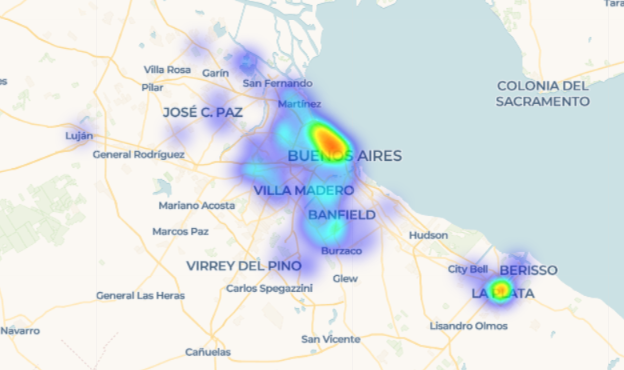

In [6]:
from IPython.display import Image
Image("fig1_heatmap.png")

### 4.3. Vehículos Utilizados en Operaciones Informales

In [ ]:
# Limpiamos la variable
vehicle = df_obs["tipo_vehiculo"].astype("string").str.strip()
vehicle = vehicle.replace(["", "nan", "None", "<NA>"], pd.NA).dropna()
vehicle = vehicle[vehicle.str.lower() != "missing"]

# Sacamos "Otro": los porcentajes se calculan sobre los vehículos clasificados
n_otro = int(vehicle.str.contains("Otro", case=False, regex=False).sum())
vehicle_grp = vehicle[~vehicle.str.contains("Otro", case=False, regex=False)]

# Nombres en inglés y sin emojis
traducciones = [
    (r"motocicleta", "Motorcycle"),
    (r"bicicleta|pat[ií]n", "Bicycle or scooter"),
    (r"cami[oó]n mediano", "Medium truck"),
    (r"cami[oó]n pesado", "Heavy truck"),
    (r"camioneta", "Pickup truck"),
    (r"autom[oó]vil", "Car"),
    (r"\bsuv\b", "SUV"),
    (r"\bvan\b", "Van"),
]

def traducir(v):
    v_low = v.lower()
    for patron, nombre in traducciones:
        if re.search(patron, v_low):
            return nombre
    return v

dos_ruedas = ["Motorcycle", "Bicycle or scooter"]
vehicle_en = vehicle_grp.map(traducir)

# Tabla de frecuencias, porcentajes y grupo
vehicle_freq = vehicle_en.value_counts().rename_axis("vehicle").reset_index(name="count")
total = vehicle_freq["count"].sum()
vehicle_freq["pct"] = vehicle_freq["count"] / total * 100
vehicle_freq["group"] = vehicle_freq["vehicle"].apply(
    lambda v: "Two-wheeled vehicles" if v in dos_ruedas else "Other vehicles"
)
vehicle_freq["label"] = vehicle_freq.apply(lambda r: f"{r['count']:,} ({r['pct']:.1f}%)", axis=1)

n_dos = int(vehicle_freq.loc[vehicle_freq["group"] == "Two-wheeled vehicles", "count"].sum())
pct_dos = n_dos / total * 100

# Gráfico combinado
fig = px.bar(
    vehicle_freq,
    x="count",
    y="vehicle",
    orientation="h",
    color="group",
    color_discrete_map={"Two-wheeled vehicles": "#1f77b4", "Other vehicles": "#a6a6a6"},
    category_orders={"group": ["Two-wheeled vehicles", "Other vehicles"]},
    text="label",
    title="Vehicle types observed in informal logistics",
    labels={"count": "Number of observations", "vehicle": "Vehicle type", "group": ""},
)

fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_yaxes(categoryorder="total ascending")
fig.update_xaxes(range=[0, vehicle_freq["count"].max() * 1.2])
fig.add_annotation(
    x=0.98, y=0.08, xref="paper", yref="paper", xanchor="right", showarrow=False, align="right",
    text=(f"Two-wheeled vehicles: {n_dos:,} ({pct_dos:.1f}%)<br>"
          f"Other vehicles: {total - n_dos:,} ({100 - pct_dos:.1f}%)"),
    font=dict(size=13),
)
fig.update_layout(
    template="simple_white",
    legend_title_text="",
    legend=dict(orientation="h", y=-0.2),
    font=dict(size=13),
    width=850, height=450,
)
# fig.show()

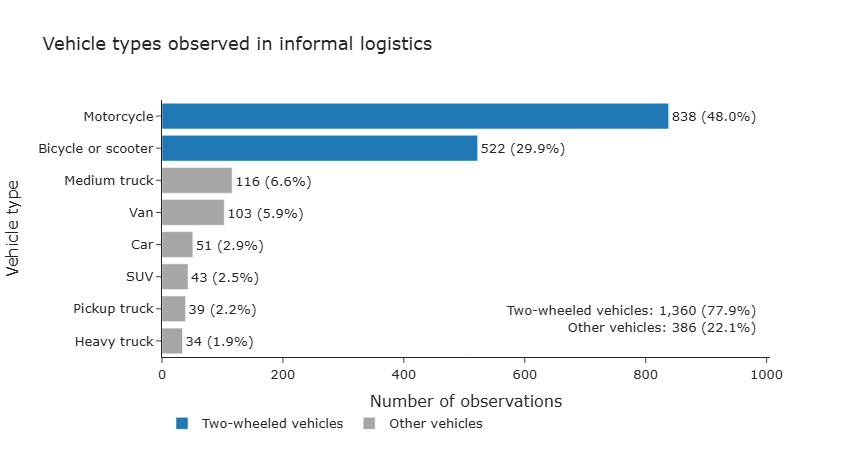

In [90]:
from IPython.display import Image
Image("fig2_vehicle_types.png")

### 4.4. Tipo de Estacionamiento Según Vehículo

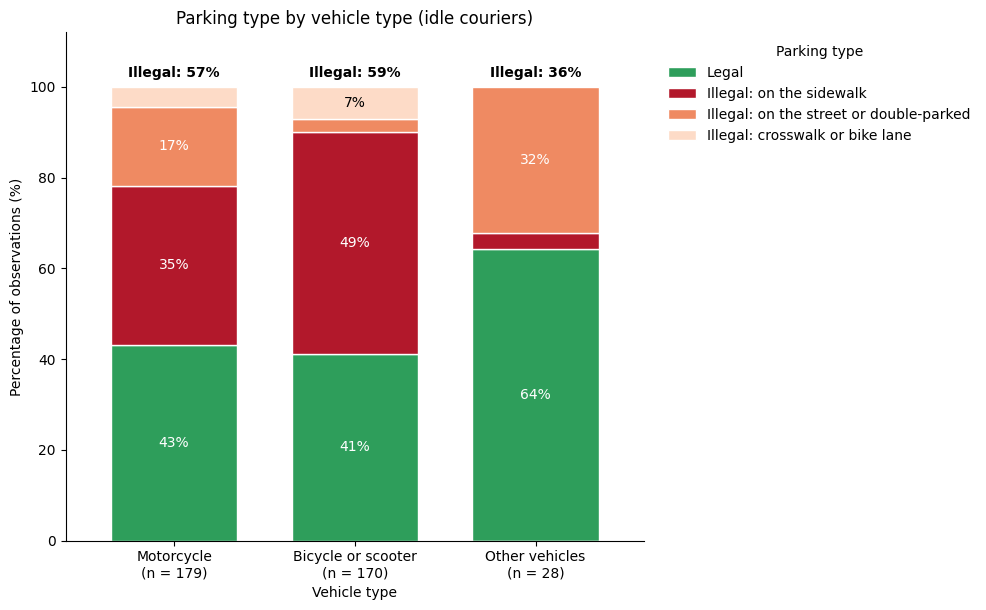

Nota para el epígrafe: se excluyen 32 observaciones con estacionamiento 'Other' o sin dato.


In [51]:
# ¿Solo observaciones de repartidores inactivos (idle)?
solo_inactivos = True

# Agrupamos el vehículo (mismos criterios que la figura de vehículos); "Otro" queda afuera
def agrupar_vehiculo(valor):
    if pd.isna(valor):
        return np.nan
    v = str(valor).lower()
    if re.search(r"motocicleta", v):
        return "Motorcycle"
    if re.search(r"bicicleta|pat[ií]n", v):
        return "Bicycle or scooter"
    if re.sub(r"[^\w]", "", v) == "otro":
        return np.nan
    return "Other vehicles"

# Clasificamos el estacionamiento, separando los tipos de ilegalidad
def clasificar_estacionamiento(valor):
    if pd.isna(valor):
        return np.nan
    v = str(valor).lower()
    if "ilegal" in v:
        if "acera" in v or "banqueta" in v:
            return "Illegal: on the sidewalk"
        if "doble" in v or "calle" in v:
            return "Illegal: on the street or double-parked"
        if "cruce" in v or "ciclov" in v:
            return "Illegal: crosswalk or bike lane"
        return "Illegal: other"
    if "legal" in v:
        return "Legal"
    return np.nan

datos = df_obs.copy()
if solo_inactivos:
    datos = datos[datos["actividad"].astype("string").str.contains("Inactivo", case=False, na=False)]

datos["vehiculo_grupo"] = datos["tipo_vehiculo"].apply(agrupar_vehiculo)
datos["estacionamiento_tipo"] = datos["estacionamiento_legal"].apply(clasificar_estacionamiento)

n_sin_clasificar = int(datos["estacionamiento_tipo"].isna().sum())
datos = datos.dropna(subset=["vehiculo_grupo", "estacionamiento_tipo"])

# Tabla cruzada (% por fila) y tamaño de cada grupo
orden_vehiculos = ["Motorcycle", "Bicycle or scooter", "Other vehicles"]
orden_tipos = ["Legal", "Illegal: on the sidewalk", "Illegal: on the street or double-parked",
               "Illegal: crosswalk or bike lane", "Illegal: other"]

conteo = pd.crosstab(datos["vehiculo_grupo"], datos["estacionamiento_tipo"]).reindex(orden_vehiculos)
tabla = conteo.div(conteo.sum(axis=1), axis=0) * 100
tabla = tabla[[c for c in orden_tipos if c in tabla.columns]]
n_por_grupo = conteo.sum(axis=1)

# Gráfico de barras apiladas
colores = {"Legal": "#2e9e5b",
           "Illegal: on the sidewalk": "#b2182b",
           "Illegal: on the street or double-parked": "#ef8a62",
           "Illegal: crosswalk or bike lane": "#fddbc7",
           "Illegal: other": "#999999"}

ax = tabla.plot(kind="bar", stacked=True, figsize=(10, 6.2),
                color=[colores[c] for c in tabla.columns], edgecolor="white", width=0.7)

# Porcentaje dentro de cada tramo
for contenedor in ax.containers:
    etiquetas = [f"{v.get_height():.0f}%" if v.get_height() >= 5 else "" for v in contenedor]
    ax.bar_label(contenedor, labels=etiquetas, label_type="center", fontsize=10,
                 color="black" if contenedor.get_label() in ("Illegal: crosswalk or bike lane",) else "white")

# Total ilegal arriba de cada barra
total_ilegal = tabla[[c for c in tabla.columns if c.startswith("Illegal")]].sum(axis=1)
for i, valor in enumerate(total_ilegal):
    ax.text(i, 101.5, f"Illegal: {valor:.0f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticklabels([f"{v}\n(n = {int(n_por_grupo[v])})" for v in tabla.index], rotation=0)
ax.set_ylim(0, 112)
ax.set_ylabel("Percentage of observations (%)")
ax.set_xlabel("Vehicle type")
ax.set_title("Parking type by vehicle type" + (" (idle couriers)" if solo_inactivos else " (all operations)"))
ax.legend(title="Parking type", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Nota para el epígrafe: se excluyen {n_sin_clasificar} observaciones con estacionamiento 'Other' o sin dato.")

### 4.5. Situaciones Adversas Reportadas por los Repartidores

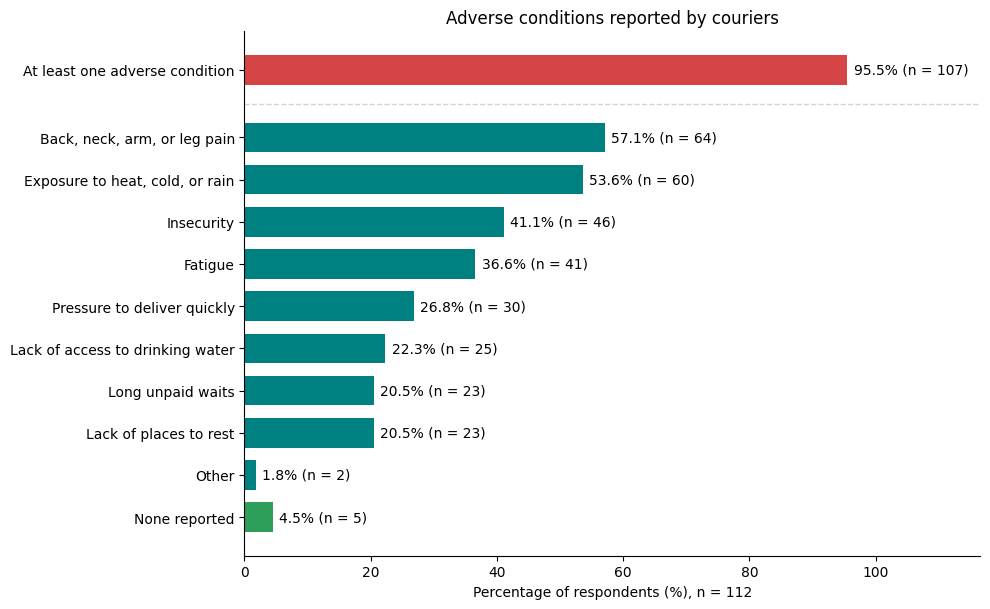

Nota para el epígrafe: pregunta de respuesta múltiple, los porcentajes de cada condición suman más de 100%. Base: 112 respondentes.
Respuestas inconsistentes ('Ninguna' + otra opción): 1, contadas como 'al menos una'.


In [52]:
# Una fila por repartidor que respondió la pregunta
encuestas = df_survey[df_survey["ResponseId"].astype(str).str.startswith("R_")]
s_cond = encuestas["condiciones_adversas_survey"].dropna()
n_resp = len(s_cond)

# Condiciones: texto de la encuesta -> nombre en inglés
condiciones = {
    "Dolor de espalda, cuello, brazos o piernas": "Back, neck, arm, or leg pain",
    "Exposición a calor, frío o lluvia": "Exposure to heat, cold, or rain",
    "Inseguridad": "Insecurity",
    "Fatiga": "Fatigue",
    "Presión para completar entregas rápidamente": "Pressure to deliver quickly",
    "Falta de acceso a agua potable": "Lack of access to drinking water",
    "Largas esperas sin pago": "Long unpaid waits",
    "Falta de lugares para descansar": "Lack of places to rest",
    "Otra": "Other",
}
conteo = {en: int(s_cond.str.contains(es, regex=False).sum()) for es, en in condiciones.items()}

# "Al menos una" vs. "Ninguna": quien marcó alguna situación cuenta como "con alguna", aunque también haya marcado "Ninguna" (respuesta inconsistente)
marco_alguna = s_cond.apply(lambda x: any(es in x for es in condiciones))
n_alguna = int(marco_alguna.sum())
n_ninguna = n_resp - n_alguna
n_inconsistentes = int((s_cond.str.contains("Ninguna", regex=False) & marco_alguna).sum())

# Filas del gráfico: resumen arriba, condiciones ordenadas, y al final "Other" y "None"
condiciones_ordenadas = sorted([(k, v) for k, v in conteo.items() if k != "Other"],
                               key=lambda x: x[1], reverse=True)
filas = ([("At least one adverse condition", n_alguna, "#d64545")]
         + [(k, v, "teal") for k, v in condiciones_ordenadas]
         + [("Other", conteo["Other"], "teal"), ("None reported", n_ninguna, "#2e9e5b")])

nombres = [f[0] for f in filas]
valores = [f[1] for f in filas]
colores = [f[2] for f in filas]
porcentajes = [v / n_resp * 100 for v in valores]
posiciones = [0] + [1.6 + i for i in range(len(filas) - 1)]

# Gráfico de barras horizontales
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.barh(posiciones, porcentajes, color=colores, height=0.7)
ax.set_yticks(posiciones)
ax.set_yticklabels(nombres)
ax.invert_yaxis()

for y, p, n in zip(posiciones, porcentajes, valores):
    ax.text(p + 1, y, f"{p:.1f}% (n = {n})", va="center", fontsize=10)

ax.axhline(0.8, color="lightgray", linestyle="--", linewidth=1)
ax.set_xlim(0, max(porcentajes) * 1.22)
ax.set_xlabel(f"Percentage of respondents (%), n = {n_resp}")
ax.set_title("Adverse conditions reported by couriers")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Nota para el epígrafe: pregunta de respuesta múltiple, los porcentajes de cada condición suman más de 100%. Base: {n_resp} respondentes.")
print(f"Respuestas inconsistentes ('Ninguna' + otra opción): {n_inconsistentes}, contadas como 'al menos una'.")

## **5. Hipótesis 1: Organización Urbana de los Repartidores en su Periodo de Inactividad**


### 5.1. Formulación



H₀: La proporción de registros de repartidores observados en situación de inactividad ubicados en la calle o afuera de un negocio no es mayor al 50%. (p<=0,50)
<br>H₁: La proporción de registros de repartidores observados en situación de inactividad ubicados en la calle o afuera de un negocio es mayor al 50%. (p>0,50)


Variable de estudio: lugar de inactividad. Cualitativa nominal.

La muestra utilizada para esta hipótesis es el subconjunto de las observaciones que respondan al tipo de operación “inactivo” y que tengan el campo "lugar de inactividad" respondido.

--- CONTEO GENERAL DE INACTIVOS ---
Total de observaciones de tipo inactivo: 409
Con lugar de inactividad válido (muestra analítica): 403
Sin dato de lugar (excluidas): 6

--- DISTRIBUCIÓN DE LAS 4 CATEGORÍAS ---


,n,porcentaje
lugar_inactividad,,
En la calle,196,48.6
Afuera de un negocio,121,30.0
En un parque público,53,13.2
Otro,33,8.2


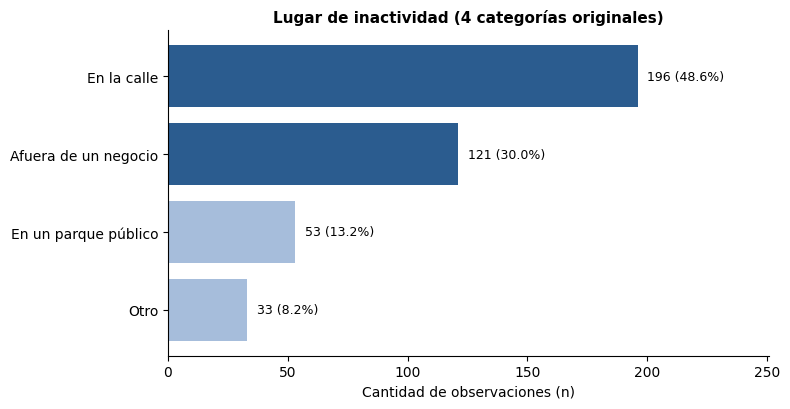

In [53]:
# Debemos tener en cuenta únicamente los registros cuyo tipo de operación sea "Inactivo"
mask_inactivos = df_obs["actividad"].astype(str).str.contains("Inactivo", case=False, na=False)
df_inactivos = df_obs[mask_inactivos].copy()

# De los inactivos, tomamos únicamente los que tengan "lugar de inactividad" respondido, esta será nuestra muestra válida
df_h1 = df_inactivos.dropna(subset=["lugar_inactividad"]).copy()

total_inactivos = len(df_inactivos)
n_h1 = len(df_h1)
n_nulos = total_inactivos - n_h1

print("--- CONTEO GENERAL DE INACTIVOS ---")
print(f"Total de observaciones de tipo inactivo: {total_inactivos}")
print(f"Con lugar de inactividad válido (muestra analítica): {n_h1}")
print(f"Sin dato de lugar (excluidas): {n_nulos}")

# Mostramos la distribución del lugar de inactividad de la muestra
orden_categorias = ["En la calle", "Afuera de un negocio", "En un parque público", "Otro"]
tabla_lugar = (
    df_h1["lugar_inactividad"].value_counts().reindex(orden_categorias).fillna(0).astype(int)
    .rename("n").to_frame()
)
tabla_lugar["porcentaje"] = (tabla_lugar["n"] / n_h1 * 100).round(1)

print("\n--- DISTRIBUCIÓN DE LAS 4 CATEGORÍAS ---")
display(tabla_lugar)


# GRÁFICO 4 CATEGORÍAS

COLOR_EXITO, COLOR_FRACASO = "#2b5c8f", "#a6bddb"

plt.figure(figsize=(8, 4.2))
ax = plt.gca()

conteos = tabla_lugar["n"]
cats = list(conteos.index)[::-1]
vals = list(conteos.values)[::-1]
colores = [COLOR_EXITO if c in ("En la calle", "Afuera de un negocio") else COLOR_FRACASO for c in cats]

ax.barh(cats, vals, color=colores)
for i, v in enumerate(vals):
    ax.text(v + n_h1 * 0.01, i, f"{v} ({v / n_h1 * 100:.1f}%)", va="center", fontsize=9)

ax.set_xlim(0, max(vals) * 1.28)
ax.set_xlabel("Cantidad de observaciones (n)")
ax.set_title("Lugar de inactividad (4 categorías originales)", fontsize=11, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()

Para el análisis de la hipótesis, la cual es descriptiva de una única variable, vamos a llevar a las posibles 4 respuestas cualitativas nominales a una cualitativa binaria, verificando si pertenece o no al grupo que estudiamos. Es decir, en este caso, estudiaríamos si el repartidor está inactivo en la calle o afuera de un negocio, o si no permanece inactivo en esos lugares.

In [54]:
# Definimos los grupos para la variable binaria
GRUPO_EXITO = "Calle o afuera de un negocio"
GRUPO_FRACASO = "Parque u otro"

def clasificar_lugar_h1(lugar):
    """Clasifica el lugar de inactividad en un grupo binario."""
    l_str = str(lugar).strip().lower()
    return GRUPO_EXITO if ("calle" in l_str or "negocio" in l_str) else GRUPO_FRACASO

assert df_h1["lugar_inactividad"].notna().all(), "Hay valores nulos en lugar_inactividad"

df_h1["lugar_binario"] = df_h1["lugar_inactividad"].map(clasificar_lugar_h1)
df_h1["exito"] = (df_h1["lugar_binario"] == GRUPO_EXITO).astype(int)

print("--- DISTRIBUCIÓN DE LA VARIABLE BINARIA ---")
print(df_h1["lugar_binario"].value_counts())

--- DISTRIBUCIÓN DE LA VARIABLE BINARIA ---
lugar_binario
Calle o afuera de un negocio    317
Parque u otro                    86
Name: count, dtype: int64


### 5.2. Diseño de la Prueba<br>


El test de prueba adecuadp es el test binomial de proporción, porque la variable de estudio es categórica y se compara una proporción contra un valor de referencia (P0 = 0,50)

Fijamos el valor de corte en base a las hipótesis planteadas

In [55]:
P0 = 0.50       # valor de referencia bajo H0

### 5.3. Resultados

In [56]:
# Tamaño muestral, éxitos y proporción observada
n = len(df_h1)
k = int(df_h1["exito"].sum())
p_obs = k / n

print("--- 1. TAMAÑO MUESTRAL Y PROPORCIÓN OBSERVADA ---")
print(f"Tamaño muestral (n): {n}")
print(f"Éxitos observados (k): {k} de {n} observaciones")
print(f"Proporción observada (p̂): {p_obs:.4f} ({p_obs*100:.2f}%)")

--- 1. TAMAÑO MUESTRAL Y PROPORCIÓN OBSERVADA ---
Tamaño muestral (n): 403
Éxitos observados (k): 317 de 403 observaciones
Proporción observada (p̂): 0.7866 (78.66%)


In [57]:
# Tamaño del efecto: diferencia en puntos porcentuales respecto de P0
dif_pp = (p_obs - P0) * 100

print("--- 2. TAMAÑO DEL EFECTO ---")
print(f"Proporción observada: {p_obs*100:.2f}%")
print(f"Valor de referencia (P0): {P0*100:.2f}%")
print(f"Diferencia: {dif_pp:+.2f} puntos porcentuales")

--- 2. TAMAÑO DEL EFECTO ---
Proporción observada: 78.66%
Valor de referencia (P0): 50.00%
Diferencia: +28.66 puntos porcentuales


In [58]:
# 3. Intervalo de Confianza de Wilson (95%)
ci = stats.binomtest(k, n, P0).proportion_ci(confidence_level=1-ALPHA, method="wilson")
ci_inf, ci_sup = ci.low, ci.high

print("--- 3. INTERVALO DE CONFIANZA ---")
print(f"IC 95% (Wilson): [{ci_inf:.4f}, {ci_sup:.4f}]  ([{ci_inf*100:.2f}%, {ci_sup*100:.2f}%])")

--- 3. INTERVALO DE CONFIANZA ---
IC 95% (Wilson): [0.7440, 0.8238]  ([74.40%, 82.38%])


In [59]:
# 4. Test binomial exacto (p-valor) y comparación con el nivel de significancia
res_binom = stats.binomtest(k, n, P0, alternative="greater")
p_valor_1 = res_binom.pvalue

print("--- 4. CONTRASTE DE HIPÓTESIS Y DECISIÓN ---")
print(f"P-valor: {fmt_p(p_valor_1)} (exacto = {p_valor_1:.2e})\n")
print(f"Nivel de significancia (alpha): {ALPHA}")

if p_valor_1 < ALPHA:
    print("-> Se rechaza H0. Existe evidencia estadística significativa para afirmar que la proporción de registros de repartidores observados en inactividad ubicados en la calle o afuera de un negocio supera el 50%.")
else:
    print("-> No se rechaza H0.")
    print("   No se encontró evidencia estadística suficiente para asegurar que la proporción supere el 50%.")

--- 4. CONTRASTE DE HIPÓTESIS Y DECISIÓN ---
P-valor: p < 0,001 (exacto = 1.74e-32)

Nivel de significancia (alpha): 0.05
-> Se rechaza H0. Existe evidencia estadística significativa para afirmar que la proporción de registros de repartidores observados en inactividad ubicados en la calle o afuera de un negocio supera el 50%.


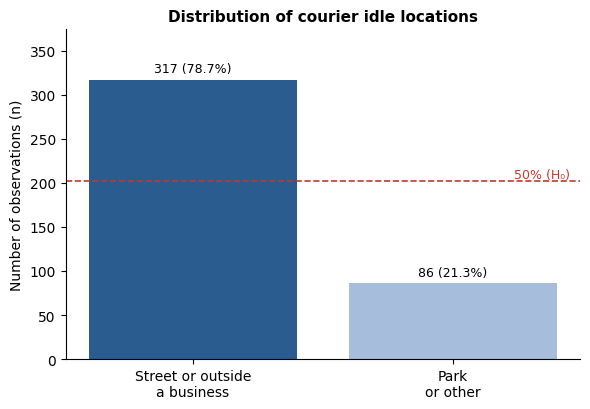

In [60]:
COLOR_EXITO, COLOR_FRACASO, COLOR_H0 = "#2b5c8f", "#a6bddb", "#c0392b"

plt.figure(figsize=(6, 4.2))
ax = plt.gca()

labels = ["Street or outside\na business", "Park\nor other"]
values = [k, n - k]
bars = ax.bar(labels, values, color=[COLOR_EXITO, COLOR_FRACASO])

for b, v in zip(bars, values):
    ax.annotate(f"{v} ({v / n * 100:.1f}%)",
                (b.get_x() + b.get_width() / 2, v),
                ha="center", va="bottom", fontsize=9,
                xytext=(0, 3), textcoords="offset points")

ax.axhline(n * P0, color=COLOR_H0, linestyle="--", linewidth=1.2)
ax.text(1.45, n * P0, " 50% (H₀)", color=COLOR_H0, va="bottom", ha="right", fontsize=9)

ax.set_ylim(0, max(values) * 1.18)
ax.set_ylabel("Number of observations (n)")
ax.set_title("Distribution of courier idle locations", fontsize=11, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()

### 5.4. Conclusiones

Agregamos también la decsión de rechazar o no H0 con el alpha laxo y el más robusto

In [61]:
# Verificación de robustez del p-valor frente a los demás niveles de significancia
print("--- ANÁLISIS DE ROBUSTEZ MULTINIVEL (H1) ---")
print(f"P-valor {p_valor_1:.4f} (exacto = {p_valor_1:.2e})\n")

# Contraste con el nivel estricto/robusto (1%)
if p_valor_1 < ALPHA_ROBUSTO:
    print(f"• Con α = {ALPHA_ROBUSTO} (Robusto): p < α -> Se rechaza H0.")
else:
    print(f"• Con α = {ALPHA_ROBUSTO} (Robusto): p >= α -> No se rechaza H0 a este nivel.")

# Contraste con el nivel laxo (10%)
if p_valor_1 < ALPHA_LAXO:
    print(f"• Con α = {ALPHA_LAXO} (Laxo): p < α -> Se rechaza H0.")
else:
    print(f"• Con α = {ALPHA_LAXO} (Laxo): p >= α -> No se rechaza H0 a este nivel.")

--- ANÁLISIS DE ROBUSTEZ MULTINIVEL (H1) ---
P-valor 0.0000 (exacto = 1.74e-32)

• Con α = 0.01 (Robusto): p < α -> Se rechaza H0.
• Con α = 0.1 (Laxo): p < α -> Se rechaza H0.


In [62]:
# CONCLUSIÓN FINAL H1 (se actualiza sola con la base utilizada)
from IPython.display import Markdown, display

coma = lambda x, f: format(x, f).replace(".", ",")

def decide_1(a):
    return "se rechaza H0" if p_valor_1 < a else "no se rechaza H0"

misma_decision = len({decide_1(ALPHA), decide_1(ALPHA_LAXO), decide_1(ALPHA_ROBUSTO)}) == 1
sentido = "por encima" if dif_pp >= 0 else "por debajo"

if p_valor_1 < ALPHA:
    resultado_1 = (f"la evidencia apoya que la proporción de registros de repartidores observados en inactividad ubicados en la calle o afuera de un negocio"
                   f"({k} de {n}, {coma(p_obs * 100, '.1f')}%; {fmt_p(p_valor_1)}).")
else:
    resultado_1 = (f"no se encontró evidencia suficiente de que la proporción de registros de repartidores que esperan en la calle o afuera de un negocio durante su inactividad supere el 50% "
                   f"({k} de {n}, {coma(p_obs * 100, '.1f')}%; {fmt_p(p_valor_1)}).")

display(Markdown(f"""
**Conclusión H1 (α = {coma(ALPHA, '.2f')}).** {decide_1(ALPHA)[0].upper() + decide_1(ALPHA)[1:]}: {resultado_1} La decisión {"es la misma" if misma_decision else "cambia"} con α = {coma(ALPHA_LAXO, '.2f')} ({decide_1(ALPHA_LAXO)}) y con α = {coma(ALPHA_ROBUSTO, '.2f')} ({decide_1(ALPHA_ROBUSTO)}).

**Tamaño del efecto e incertidumbre.** La proporción observada está {coma(abs(dif_pp), '.1f')} puntos porcentuales {sentido} del valor de referencia (50%). El IC 95% de Wilson va de {coma(ci_inf * 100, '.1f')}% a {coma(ci_sup * 100, '.1f')}%.

**Limitaciones.** La muestra no es probabilística y proviene de las zonas recorridas por los equipos; las observaciones de un mismo observador o zona pueden no ser independientes (supuesto del test binomial); "Otro" se asignó al grupo de comparación; los {n_nulos} registros sin dato de lugar se excluyeron. La ficha registra dónde están los repartidores, no por qué (no distingue descanso de espera de pedidos).
"""))


**Conclusión H1 (α = 0,05).** Se rechaza H0: la evidencia apoya que la proporción de registros de repartidores observados en inactividad ubicados en la calle o afuera de un negocio(317 de 403, 78,7%; p < 0,001). La decisión es la misma con α = 0,10 (se rechaza H0) y con α = 0,01 (se rechaza H0).

**Tamaño del efecto e incertidumbre.** La proporción observada está 28,7 puntos porcentuales por encima del valor de referencia (50%). El IC 95% de Wilson va de 74,4% a 82,4%.

**Limitaciones.** La muestra no es probabilística y proviene de las zonas recorridas por los equipos; las observaciones de un mismo observador o zona pueden no ser independientes (supuesto del test binomial); "Otro" se asignó al grupo de comparación; los 6 registros sin dato de lugar se excluyeron. La ficha registra dónde están los repartidores, no por qué (no distingue descanso de espera de pedidos).


## **6. Hipótesis 2: ¿Cómo se Relaciona el Tipo de Vehículo con el Lugar de Inactividad?**

### 6.1. Formulación

H0: la distribución de los lugares de inactividad es independiente del tipo de vehículo. <br>
H1: la distribución de los lugares de inactividad se asocia con el tipo de vehículo.

Variable X (Independiente): Tipo de vehículo. Cualitativa nominal

Variable Y (Dependiente): Lugar de inactividad. Cualitativa nominal

La variable tipo de vehículo vamos a agruparla en 3 categorías: bicicleta o patín (scooter), motocicleta y otros motorizados. Lo mismo para el lugar de espera, en las siguientes categorías: en la calle, afuera de un negocio y en un parque público u otro. Esto porque, con las categorías originales, muchas celdas de la tabla de contingencia tendrían una frecuencia esperada menor a 5, por lo que no se cumpliría el supuesto del chi-cuadrado. La guía indica en ese caso colapsar categorías o usar el test exacto de Fisher; se eligió agrupar según la lógica operativa: "otros motorizados" reúne el resto de los vehículos motorizados (autos, camionetas, vans, camiones y otros) y "parque público u otro" reúne las dos categorías de lugar menos frecuentes. Así se pasa de la tabla original a una de 3x3.

La muestra de la base de datos serán aquellas observaciones que tengan como tipo de operación "inactivo" y que tengan "lugar de inactividad" respondido

In [63]:
# Filtramos nuevamente el subconjunto de inactivos con datos válidos para ambas variables
df_h2 = df_inactivos.dropna(subset=["tipo_vehiculo", "lugar_inactividad"]).copy()

# Función de agrupación para el tipo de vehículo (Variable X) en 3 categorías
def agrupar_vehiculo(vehiculo):
    v = str(vehiculo).strip().lower()
    if "bicicleta" in v or "patín" in v or "scooter" in v:
        return "Bicicleta o patín"
    elif "motocicleta" in v or "moto" in v:
        return "Motocicleta"
    else:
        return "Otros motorizados"

# Función de agrupación para el lugar de inactividad (Variable Y) en 3 categorías
def agrupar_lugar(lugar):
    l = str(lugar).strip().lower()
    if "calle" in l:
        return "En la calle"
    elif "negocio" in l:
        return "Afuera de un negocio"
    else:
        return "Parque público u otro"

# Aplicamos las agrupaciones
df_h2["vehiculo_categoría"] = df_h2["tipo_vehiculo"].map(agrupar_vehiculo)
df_h2["lugar_categoría"] = df_h2["lugar_inactividad"].map(agrupar_lugar)

# Construimos la tabla de contingencia (frecuencias observadas)
tabla_contingencia = pd.crosstab(
    df_h2["vehiculo_categoría"],
    df_h2["lugar_categoría"]
)

print("--- TABLA DE CONTINGENCIA (3x3) ---")
display(tabla_contingencia)
print(f"\nTotal de observaciones analizadas para H2 (n): {len(df_h2)}")

--- TABLA DE CONTINGENCIA (3x3) ---


lugar_categoría,Afuera de un negocio,En la calle,Parque público u otro
vehiculo_categoría,,,
Bicicleta o patín,47,87,54
Motocicleta,70,90,24
Otros motorizados,4,19,8



Total de observaciones analizadas para H2 (n): 403


### 6.2. Diseño de la Prueba

Prueba: chi-cuadrado de independencia, porque ambas variables son cualitativas. Nivel de significancia: α = 0,05 (definido en la sección 3).

El supuesto que debemos verificar es el de frecuencias esperadas, el cual se verifica calculando las frecuencias esperadas de cada celda bajo independencia (total de la fila x total de la columna / n) y se comprueba que ninguna sea menor a 5. Si alguna lo fuera, se usaría el test exacto de Fisher.

In [64]:
# Ejecutamos chi2_contingency para obtener las frecuencias esperadas teóricas
chi2_stat, p_valor_2, dof, esperadas = chi2_contingency(tabla_contingencia)

# Convertimos el array de esperadas en un DataFrame para visualizarlo ordenado
df_esperadas = pd.DataFrame(
    esperadas,
    index=tabla_contingencia.index,
    columns=tabla_contingencia.columns
).round(2)

print("--- FRECUENCIAS ESPERADAS TEÓRICAS (E_ij) ---")
display(df_esperadas)

# Verificamos si alguna celda tiene frecuencia esperada menor a 5
min_esperada = esperadas.min()
menores_a_5 = (esperadas < 5).sum()

print(f"\nFrecuencia esperada mínima en las celdas: {min_esperada:.2f}")
print(f"Cantidad de celdas con frecuencia esperada < 5: {menores_a_5}")

if menores_a_5 > 0:
    print("\n-> ALERTA DE SUPUESTO: Se detectó al menos una celda con frecuencia esperada menor a 5.")
    print("   Tal como se indicó en el diseño, esto requiere el uso del Test Exacto de Fisher como alternativa robusta.")
else:
    print("\n-> SUPUESTO CUMPLIDO: Todas las frecuencias esperadas son mayores o iguales a 5.")
    print("   Es plenamente válido proceder con el Test de Chi-cuadrado de independencia.")

--- FRECUENCIAS ESPERADAS TEÓRICAS (E_ij) ---


lugar_categoría,Afuera de un negocio,En la calle,Parque público u otro
vehiculo_categoría,,,
Bicicleta o patín,56.45,91.43,40.12
Motocicleta,55.25,89.49,39.27
Otros motorizados,9.31,15.08,6.62



Frecuencia esperada mínima en las celdas: 6.62
Cantidad de celdas con frecuencia esperada < 5: 0

-> SUPUESTO CUMPLIDO: Todas las frecuencias esperadas son mayores o iguales a 5.
   Es plenamente válido proceder con el Test de Chi-cuadrado de independencia.


Como el supuesto se verificó, proseguimos con el test planteado inicialmente.

### 6.3. Resultados

Calculamos el tamaño muestral final y comprobamos la distribución por el tipo de vehículo

In [65]:
# 1. Tamaño muestral
print("--- 1. TAMAÑO MUESTRAL (H2) ---")
print(f"Observaciones de tipo inactivo: {len(df_inactivos)}")
print(f"Con tipo de vehículo y lugar de inactividad respondidos (n): {len(df_h2)}")
print(f"Excluidas por no tener alguno de los dos datos: {len(df_inactivos) - len(df_h2)}")

print("\nPor tipo de vehículo (agrupado):")
display(df_h2["vehiculo_categoría"].value_counts().rename("n").to_frame())

print("Por lugar de inactividad (agrupado):")
display(df_h2["lugar_categoría"].value_counts().rename("n").to_frame())

--- 1. TAMAÑO MUESTRAL (H2) ---
Observaciones de tipo inactivo: 409
Con tipo de vehículo y lugar de inactividad respondidos (n): 403
Excluidas por no tener alguno de los dos datos: 6

Por tipo de vehículo (agrupado):


,n
vehiculo_categoría,
Bicicleta o patín,188
Motocicleta,184
Otros motorizados,31


Por lugar de inactividad (agrupado):


,n
lugar_categoría,
En la calle,196
Afuera de un negocio,121
Parque público u otro,86


Estadístico de prueba: se calcula el chi-cuadrado (χ²) y sus grados de libertad.

In [66]:
# 2. Estadístico de prueba (Chi-cuadrado y grados de libertad)
chi2_stat, p_valor_2, dof, esperadas = chi2_contingency(tabla_contingencia)
n_h2 = len(df_h2)

print("--- 1. ESTADÍSTICO DE PRUEBA (CHI-CUADRADO) ---")
print(f"Estadístico χ²: {chi2_stat:.4f}")
print(f"Grados de libertad (dof): {dof}")
print(f"Tamaño muestral (n): {n_h2}")

--- 1. ESTADÍSTICO DE PRUEBA (CHI-CUADRADO) ---
Estadístico χ²: 20.8142
Grados de libertad (dof): 4
Tamaño muestral (n): 403


Tamaño del efecto: V de Cramér

In [67]:
# 3. Tamaño del efecto: V de Cramér
min_dim = min(tabla_contingencia.shape[0] - 1, tabla_contingencia.shape[1] - 1)
v_cramer = np.sqrt(chi2_stat / (n_h2 * min_dim))

if v_cramer < 0.2:
    interp_v = "asociación débil"
elif v_cramer < 0.4:
    interp_v = "asociación moderada"
else:
    interp_v = "asociación fuerte"

print("--- 2. TAMAÑO DEL EFECTO (V DE CRAMÉR) ---")
print(f"V de Cramér: {v_cramer:.4f}")
print(f"Interpretación de la magnitud: {interp_v}")

--- 2. TAMAÑO DEL EFECTO (V DE CRAMÉR) ---
V de Cramér: 0.1607
Interpretación de la magnitud: asociación débil


Se compara el p-valor con α = 0,05. Si p < α, se rechaza H0.

In [68]:
# 4. P-valor y contraste de hipótesis
print("--- 4. CONTRASTE DE HIPÓTESIS Y DECISIÓN ---")
print(f"P-valor: {fmt_p(p_valor_2)} (exacto = {p_valor_2:.2e})")
print(f"Nivel de significancia (alpha): {ALPHA}")

if p_valor_2 < ALPHA:
    print("-> Se rechaza H0. Existe evidencia estadística significativa para afirmar que el lugar de inactividad se asocia con el tipo de vehículo")
else:
    print("-> No se rechaza H0. No se encontró evidencia estadística suficiente para asegurar una asociación entre ambas variables.")

--- 4. CONTRASTE DE HIPÓTESIS Y DECISIÓN ---
P-valor: p < 0,001 (exacto = 3.45e-04)
Nivel de significancia (alpha): 0.05
-> Se rechaza H0. Existe evidencia estadística significativa para afirmar que el lugar de inactividad se asocia con el tipo de vehículo


Generamos un gráfico de barras que muestra la distribución del lugar de inactividad según el vehículo

<Figure size 1000x500 with 0 Axes>

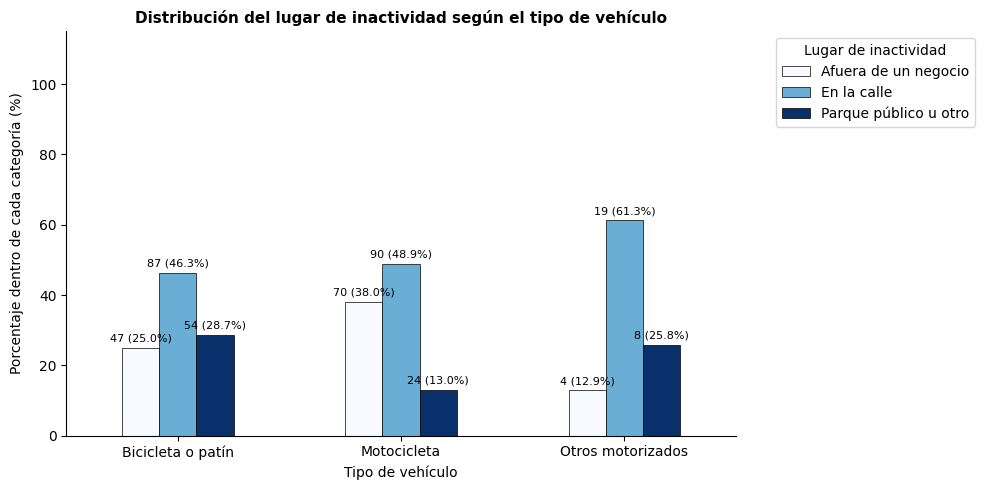

In [69]:
# GRÁFICO DE BARRAS AGRUPADAS CON ETIQUETAS DE FRECUENCIA Y PORCENTAJE
tabla_conteo = pd.crosstab(df_h2["vehiculo_categoría"], df_h2["lugar_categoría"])
tabla_porcentajes = tabla_conteo.div(tabla_conteo.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 5))
ax = tabla_porcentajes.plot(
    kind="bar",
    figsize=(10, 5),
    colormap="Blues",
    edgecolor="black",
    linewidth=0.5
)

plt.title("Distribución del lugar de inactividad según el tipo de vehículo", fontsize=11, fontweight="bold")
plt.xlabel("Tipo de vehículo", fontsize=10)
plt.ylabel("Porcentaje dentro de cada categoría (%)", fontsize=10)
plt.xticks(rotation=0)
plt.legend(title="Lugar de inactividad", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.ylim(0, 115)

# Recorremos cada grupo de barras (cada columna de la tabla de contingencia) para poner las etiquetas
for i, container in enumerate(ax.containers):
    # Obtenemos la serie de conteos absolutos correspondiente a esta categoría
    col_name = tabla_conteo.columns[i]
    conteos_col = tabla_conteo[col_name].values

    # Lista para guardar los textos formateados
    labels = [f"{val} ({pct:.1f}%)" for val, pct in zip(conteos_col, container.datavalues)]

    # Agregamos las etiquetas arriba de cada barra del contenedor
    ax.bar_label(container, labels=labels, padding=3, rotation=0, fontsize=8)

sns.despine()
plt.tight_layout()
plt.show()

### 6.4. Conclusiones

Antes de pasar a las conclusiones de la hipótesis 2, algo nos llama la atención: una parte de los otros motorizados espera en 'parque público u otro'. Nuestra duda es cuántos esperan realmente en un parque público. Para verlo, se muestran los 4 lugares originales según el grupo de vehículo. Es un análisis descriptivo, sin prueba de hipótesis.

--- FRECUENCIAS ---


lugar_inactividad,En la calle,Afuera de un negocio,En un parque público,Otro
vehiculo_categoría,,,,
Bicicleta o patín,87,47,38,16
Motocicleta,90,70,14,10
Otros motorizados,19,4,1,7


--- PORCENTAJES DENTRO DE CADA GRUPO DE VEHÍCULO ---


lugar_inactividad,En la calle,Afuera de un negocio,En un parque público,Otro
vehiculo_categoría,,,,
Bicicleta o patín,46.3,25.0,20.2,8.5
Motocicleta,48.9,38.0,7.6,5.4
Otros motorizados,61.3,12.9,3.2,22.6


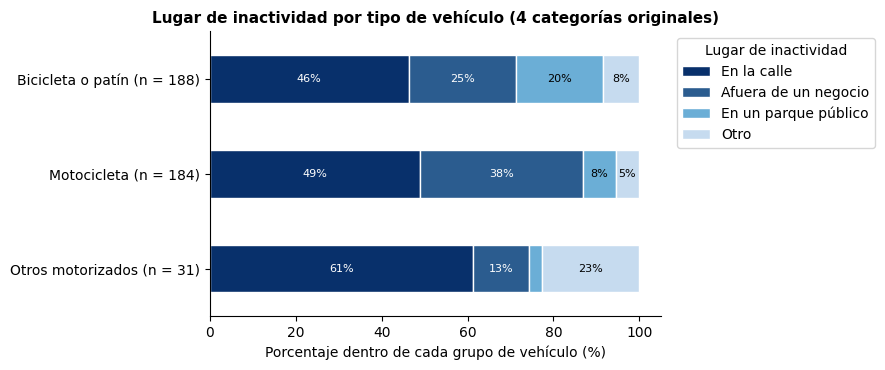

In [70]:
# Anáisis exploratorio del lugar de inactividad con las 4 categorías originales según el grupo de vehículo
orden_lugares = ["En la calle", "Afuera de un negocio", "En un parque público", "Otro"]

tabla_4cat = (
    pd.crosstab(df_h2["vehiculo_categoría"], df_h2["lugar_inactividad"])
    .reindex(columns=orden_lugares, fill_value=0)
)
tabla_4cat_pct = (tabla_4cat.div(tabla_4cat.sum(axis=1), axis=0) * 100).round(1)

print("--- FRECUENCIAS ---")
display(tabla_4cat)
print("--- PORCENTAJES DENTRO DE CADA GRUPO DE VEHÍCULO ---")
display(tabla_4cat_pct)

tabla_grafico = tabla_4cat_pct.copy()
tabla_grafico.index = [f"{grupo} (n = {total})" for grupo, total in tabla_4cat.sum(axis=1).items()]

colores_4cat = ["#08306b", "#2b5c8f", "#6baed6", "#c6dbef"]
ax = tabla_grafico.plot(kind="barh", stacked=True, color=colores_4cat, edgecolor="white", figsize=(9, 3.8))

for i, contenedor in enumerate(ax.containers):
    ax.bar_label(contenedor,
                 labels=[f"{v:.0f}%" if v >= 5 else "" for v in contenedor.datavalues],
                 label_type="center", fontsize=8, color="white" if i < 2 else "black")

ax.invert_yaxis()
ax.set_xlabel("Porcentaje dentro de cada grupo de vehículo (%)")
ax.set_title("Lugar de inactividad por tipo de vehículo (4 categorías originales)", fontsize=11, fontweight="bold")
ax.legend(title="Lugar de inactividad", bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine()
plt.tight_layout()
plt.show()

Verificamos también si se rechazaría H0 o no con los distintos niveles de alpha fijados

In [71]:
# Verificación de robustez del p-valor frente a los demás niveles de significancia
print("--- ANÁLISIS DE ROBUSTEZ MULTINIVEL (H2) ---")
print(f"P-valor {p_valor_2:.4f} (exacto = {p_valor_2:.2e})\n")

# Contraste con el nivel estricto/robusto (1%)
if p_valor_2 < ALPHA_ROBUSTO:
    print(f"• Con α = {ALPHA_ROBUSTO} (Robusto): p < α -> Se rechaza H0.")
else:
    print(f"• Con α = {ALPHA_ROBUSTO} (Robusto): p >= α -> No se rechaza H0 a este nivel.")

# Contraste con el nivel laxo (10%)
if p_valor_2 < ALPHA_LAXO:
    print(f"• Con α = {ALPHA_LAXO} (Laxo): p < α -> Se rechaza H0.")
else:
    print(f"• Con α = {ALPHA_LAXO} (Laxo): p >= α -> No se rechaza H0 a este nivel.")

--- ANÁLISIS DE ROBUSTEZ MULTINIVEL (H2) ---
P-valor 0.0003 (exacto = 3.45e-04)

• Con α = 0.01 (Robusto): p < α -> Se rechaza H0.
• Con α = 0.1 (Laxo): p < α -> Se rechaza H0.


In [72]:
# CONCLUSIÓN FINAL H2 (se actualiza sola con la base utilizada)
from IPython.display import Markdown, display

coma = lambda x, f: format(x, f).replace(".", ",")

def decide(a):
    return "se rechaza H0" if p_valor_2 < a else "no se rechaza H0"

misma_decision = len({decide(ALPHA), decide(ALPHA_LAXO), decide(ALPHA_ROBUSTO)}) == 1

# Patrón descriptivo: porcentaje de cada lugar dentro de cada grupo de vehículo
pct_2 = tabla_contingencia.div(tabla_contingencia.sum(axis=1), axis=0) * 100
lugar_mas_usado = "; ".join(
    f"{grupo.lower()}: {pct_2.loc[grupo].idxmax().lower()} ({coma(pct_2.loc[grupo].max(), '.1f')}%)"
    for grupo in pct_2.index
)
mayor_negocio = pct_2["Afuera de un negocio"].idxmax().lower()
mayor_parque = pct_2["Parque público u otro"].idxmax().lower()
n_otros = int(tabla_contingencia.loc["Otros motorizados"].sum())

if p_valor_2 < ALPHA:
    resultado_2 = (f"la evidencia apoya que el lugar de inactividad se asocia con el tipo de vehículo "
                   f"(χ² = {coma(chi2_stat, '.2f')}, {dof} gl, {fmt_p(p_valor_2)}; V de Cramér = {coma(v_cramer, '.2f')}, {interp_v}).")
    descriptivo_2 = (f" Descriptivamente, el lugar más frecuente dentro de cada grupo es: {lugar_mas_usado}. "
                     f"El mayor porcentaje afuera de un negocio corresponde a {mayor_negocio}, y el de parque público u otro, a {mayor_parque}.")
else:
    resultado_2 = (f"no se encontró evidencia suficiente de asociación entre el tipo de vehículo y el lugar de inactividad "
                   f"(χ² = {coma(chi2_stat, '.2f')}, {dof} gl, {fmt_p(p_valor_2)}).")
    descriptivo_2 = ""

display(Markdown(f"""
**Conclusión H2 (α = {coma(ALPHA, '.2f')}).** {decide(ALPHA)[0].upper() + decide(ALPHA)[1:]}: {resultado_2} La decisión {"es la misma" if misma_decision else "cambia"} con α = {coma(ALPHA_LAXO, '.2f')} ({decide(ALPHA_LAXO)}) y con α = {coma(ALPHA_ROBUSTO, '.2f')} ({decide(ALPHA_ROBUSTO)}).{descriptivo_2}

**Limitaciones.** La muestra no es probabilística, las observaciones de un mismo observador o zona pueden no ser independientes y el grupo "otros motorizados" tiene pocas observaciones (n = {n_otros}). Se observa una asociación, que no implica causalidad.
"""))


**Conclusión H2 (α = 0,05).** Se rechaza H0: la evidencia apoya que el lugar de inactividad se asocia con el tipo de vehículo (χ² = 20,81, 4 gl, p < 0,001; V de Cramér = 0,16, asociación débil). La decisión es la misma con α = 0,10 (se rechaza H0) y con α = 0,01 (se rechaza H0). Descriptivamente, el lugar más frecuente dentro de cada grupo es: bicicleta o patín: en la calle (46,3%); motocicleta: en la calle (48,9%); otros motorizados: en la calle (61,3%). El mayor porcentaje afuera de un negocio corresponde a motocicleta, y el de parque público u otro, a bicicleta o patín.

**Limitaciones.** La muestra no es probabilística, las observaciones de un mismo observador o zona pueden no ser independientes y el grupo "otros motorizados" tiene pocas observaciones (n = 31). Se observa una asociación, que no implica causalidad.


## **7. Hipótesis 3: Tiempo de Espera Por Falta de Pedidos Según el Tipo de Vehículo**

### 7.1. Formulación

H0: el tiempo diario de espera por falta de pedidos (y la proporción de la jornada dedicada a esperar) no difiere entre los repartidores que operan con motocicleta y los que operan en bicicleta o patín.

H1: el tiempo diario de espera por falta de pedidos (y la proporción de la jornada dedicada a esperar) difiere entre los repartidores que operan con motocicleta y los que operan en bicicleta o patín.

Variable X (independiente): tipo de vehículo observado. Cualitativa nominal.

Variable Y₁ (dependiente): horas diarias de espera por falta de pedidos. Cuantitativa discreta.

Variable Y₂ (dependiente): proporción de la jornada dedicada a esperar. Cuantitativa continua. Se calcula como:

Proporción de espera = horas de espera por falta de pedidos / horas totales de jornada

La muestra son las encuestas a repartidores que declararon sus horas diarias de espera (para Y₁) y que, además, declararon sus horas de trabajo y de descanso (para Y₂, que necesita la jornada total), y que se pueden vincular, mediante el ObservationID, con una observación de campo de motocicleta o de bicicleta o patín. El tipo de vehículo sale de esa observación, porque la encuesta no lo pregunta.

Se vincula cada encuesta con su observación de campo a través del ObservationID y se cuenta cuántos registros quedan en cada paso (incluyendo cuántos declararon, además de las horas de espera, las de trabajo y de descanso).

In [73]:
enc = df_survey.copy()
enc["horas_espera"] = pd.to_numeric(enc["horas_espera"], errors="coerce")
enc["horas_trabajo"] = pd.to_numeric(enc["Q3_HORAS_TRABAJO_1"], errors="coerce")
enc["horas_descanso"] = pd.to_numeric(enc["Q4_HORAS_DESCANSO_1"], errors="coerce")
enc = enc[enc["ObservationID"].astype(str).str.startswith("R_")].copy()

# Observaciones de campo: identificador y tipo de vehículo observado
obs = df_obs[df_obs["ResponseId"].astype(str).str.startswith("R_")][["ResponseId", "tipo_vehiculo"]].copy()

# Vinculamos cada encuesta con su observación de campo
vinculo = enc.merge(obs, left_on="ObservationID", right_on="ResponseId", how="inner", suffixes=("", "_obs"))

total_encuestas = int(df_survey["ResponseId"].astype(str).str.startswith("R_").sum())

print("--- VINCULACIÓN ENCUESTA - OBSERVACIÓN ---")
print(f"Encuestas a repartidores: {total_encuestas}")
print(f"Con ObservationID válido: {len(enc)}")
print(f"Vinculadas a una observación de campo: {len(vinculo)}")
print(f"  con horas de espera declaradas: {int(vinculo['horas_espera'].notna().sum())}")
print(f"  con horas de espera, trabajo y descanso declaradas: "
      f"{int(vinculo[['horas_espera', 'horas_trabajo', 'horas_descanso']].notna().all(axis=1).sum())}")   # NUEVO

--- VINCULACIÓN ENCUESTA - OBSERVACIÓN ---
Encuestas a repartidores: 151
Con ObservationID válido: 145
Vinculadas a una observación de campo: 95
  con horas de espera declaradas: 84
  con horas de espera, trabajo y descanso declaradas: 80


Solo vamos a utilizar las observaciones que correspondan a los tipos de vehículos "motocicleta" o "bicicleta o patín", y nos quedamos con un solo registro por ObservationID. En esta celda también calculamos Y₂ (proporción de espera) y mostramos los descriptivos de Y₁ y de Y₂ por grupo.

In [74]:
def clasificar_vehiculo_h3(vehiculo):
    """Clasifica el vehículo observado en uno de los dos grupos de la hipótesis."""
    v = str(vehiculo).strip().lower()
    if "motocicleta" in v:
        return "Motocicleta"
    if "bicicleta" in v or "patín" in v or "scooter" in v:
        return "Bicicleta o patín"
    return np.nan

vinculo["grupo"] = vinculo["tipo_vehiculo"].map(clasificar_vehiculo_h3)

# Muestra: con horas de espera declaradas, vehículo moto o bici/patín y un solo registro por observación
con_horas = vinculo.dropna(subset=["horas_espera"])
moto_bici = con_horas.dropna(subset=["grupo"])
df_h3 = moto_bici.drop_duplicates(subset="ObservationID", keep="first").copy()

# NUEVO - Variable Y2: proporción de espera = horas de espera / horas totales de jornada
df_h3["horas_jornada"] = df_h3[["horas_trabajo", "horas_descanso", "horas_espera"]].sum(axis=1, skipna=False)
df_h3["prop_espera"] = np.where(df_h3["horas_jornada"] > 0, df_h3["horas_espera"] / df_h3["horas_jornada"], np.nan)
df_h3_p = df_h3.dropna(subset=["prop_espera"]).copy()

print("--- MUESTRA DE LA HIPÓTESIS 3 ---")
print(f"Con vehículo observado moto o bicicleta/patín: {len(moto_bici)}")
print(f"Duplicados de ObservationID descartados: {len(moto_bici) - len(df_h3)}")
print(f"Muestra analítica para Y1, horas de espera (n): {len(df_h3)}")
print(f"Muestra analítica para Y2, proporción de espera (n): {len(df_h3_p)} "
      f"(se pierden {len(df_h3) - len(df_h3_p)} por no declarar horas de trabajo o de descanso)")

# Descriptivos de Y1: horas de espera por grupo
orden_grupos = ["Motocicleta", "Bicicleta o patín"]
tabla_h3 = (
    df_h3.groupby("grupo")["horas_espera"]
    .agg(n="count", media="mean", mediana="median", desvio="std")
    .reindex(orden_grupos)
    .round(2)
)

print("\n--- Y1: HORAS DIARIAS DE ESPERA POR GRUPO ---")
display(tabla_h3)
print(f"Casos en el tope del slider (10 horas): {int((df_h3['horas_espera'] == 10).sum())}")

# Descriptivos de Y2: proporción de espera por grupo (en %)
tabla_h3_p = (
    df_h3_p.assign(prop_pct=df_h3_p["prop_espera"] * 100)
    .groupby("grupo")["prop_pct"]
    .agg(n="count", media="mean", mediana="median", desvio="std")
    .reindex(orden_grupos)
    .round(1)
)
print("\n--- Y2: PROPORCIÓN DE LA JORNADA ESPERANDO (%) POR GRUPO ---")
display(tabla_h3_p)

--- MUESTRA DE LA HIPÓTESIS 3 ---
Con vehículo observado moto o bicicleta/patín: 66
Duplicados de ObservationID descartados: 1
Muestra analítica para Y1, horas de espera (n): 65
Muestra analítica para Y2, proporción de espera (n): 63 (se pierden 2 por no declarar horas de trabajo o de descanso)

--- Y1: HORAS DIARIAS DE ESPERA POR GRUPO ---


,n,media,mediana,desvio
grupo,,,,
Motocicleta,42,1.21,1.0,1.05
Bicicleta o patín,23,1.91,1.0,2.19


Casos en el tope del slider (10 horas): 1

--- Y2: PROPORCIÓN DE LA JORNADA ESPERANDO (%) POR GRUPO ---


,n,media,mediana,desvio
grupo,,,,
Motocicleta,41,10.0,9.1,7.8
Bicicleta o patín,22,13.7,10.1,12.2


Separamos la muestra en los dos grupos de vehículos y guardamos el tamaño de cada uno, para Y₁ y para Y₂. Y₂ puede tener menos casos que Y₁, porque exige que el repartidor haya declarado también sus horas de trabajo y de descanso.

In [75]:
# Y1: horas de espera
g_moto = df_h3[df_h3["grupo"] == "Motocicleta"]["horas_espera"]
g_bici = df_h3[df_h3["grupo"] == "Bicicleta o patín"]["horas_espera"]

n_moto = len(g_moto)
n_bici = len(g_bici)

# Y2: proporción de espera (0 a 1)
g_moto_p = df_h3_p[df_h3_p["grupo"] == "Motocicleta"]["prop_espera"]
g_bici_p = df_h3_p[df_h3_p["grupo"] == "Bicicleta o patín"]["prop_espera"]

n_moto_p = len(g_moto_p)
n_bici_p = len(g_bici_p)

### 7.2. Diseño de la Prueba

Las dos variables dependientes (Y₁ e Y₂) son cuantitativas y se comparan entre 2 grupos independientes (motocicleta y bicicleta o patín), por lo que la prueba a realizar es el t-test de muestras independientes o, si no se cumple la normalidad, Mann-Whitney U. La normalidad se verifica con Shapiro-Wilk en cada grupo (ambos tienen menos de 50 casos). Nivel de significancia: α = 0,05 (definido en la sección 3). Como se evalúan dos variables dependientes para una misma hipótesis, también se informa la decisión con la corrección de Bonferroni (α/2 = 0,025).

In [76]:
sw_moto = stats.shapiro(g_moto)
sw_bici = stats.shapiro(g_bici)
sw_moto_p = stats.shapiro(g_moto_p)
sw_bici_p = stats.shapiro(g_bici_p)

print("--- VERIFICACIÓN DE NORMALIDAD (Shapiro-Wilk) ---")
print("Y1: horas de espera")
print(f"  Motocicleta: W = {sw_moto.statistic:.3f}, {fmt_p(sw_moto.pvalue)}")
print(f"  Bicicleta o patín: W = {sw_bici.statistic:.3f}, {fmt_p(sw_bici.pvalue)}")
print("Y2: proporción de espera")
print(f"  Motocicleta: W = {sw_moto_p.statistic:.3f}, {fmt_p(sw_moto_p.pvalue)}")
print(f"  Bicicleta o patín: W = {sw_bici_p.statistic:.3f}, {fmt_p(sw_bici_p.pvalue)}")

if sw_moto.pvalue < ALPHA or sw_bici.pvalue < ALPHA:
    print("-> Y1: normalidad NO cumplida en al menos un grupo: corresponde Mann-Whitney U.")
else:
    print("-> Y1: normalidad cumplida en ambos grupos: correspondería el t-test de muestras independientes.")

if sw_moto_p.pvalue < ALPHA or sw_bici_p.pvalue < ALPHA:
    print("-> Y2: normalidad NO cumplida en al menos un grupo: corresponde Mann-Whitney U.")
else:
    print("-> Y2: normalidad cumplida en ambos grupos: correspondería el t-test de muestras independientes.")

--- VERIFICACIÓN DE NORMALIDAD (Shapiro-Wilk) ---
Y1: horas de espera
  Motocicleta: W = 0.797, p < 0,001
  Bicicleta o patín: W = 0.684, p < 0,001
Y2: proporción de espera
  Motocicleta: W = 0.924, p = 0,009
  Bicicleta o patín: W = 0.886, p = 0,016
-> Y1: normalidad NO cumplida en al menos un grupo: corresponde Mann-Whitney U.
-> Y2: normalidad NO cumplida en al menos un grupo: corresponde Mann-Whitney U.


Al no cumplirse el supuesto de normalidad, se aplica el test Mann-Whitney U, tanto para Y₁ como para Y₂. Por eso no se verifica la homocedasticidad (test de Levene), que corresponde solo al t-test.

El otro supuesto a verificar es el de independencia entre las observaciones. Este queda asumido al conservar un solo registro por ObservationID y considerar que cada encuesta corresponde a un repartidor distinto.

### 7.3. Resultados

Tamaño muestral y estadísticos descriptivos de cada grupo, para Y₁ (horas de espera) y para Y₂ (proporción de la jornada esperando, en %).

In [77]:
print("--- 1. TAMAÑO MUESTRAL Y DESCRIPTIVOS ---")
print("Y1: horas diarias de espera")
print(f"  Motocicleta: n = {n_moto} | media = {g_moto.mean():.2f} h | mediana = {g_moto.median():.2f} h | desvío = {g_moto.std():.2f}")
print(f"  Bicicleta o patín: n = {n_bici} | media = {g_bici.mean():.2f} h | mediana = {g_bici.median():.2f} h | desvío = {g_bici.std():.2f}")
print("Y2: proporción de la jornada esperando (%)")
print(f"  Motocicleta: n = {n_moto_p} | media = {g_moto_p.mean()*100:.1f}% | mediana = {g_moto_p.median()*100:.1f}% | desvío = {g_moto_p.std()*100:.1f} pp")
print(f"  Bicicleta o patín: n = {n_bici_p} | media = {g_bici_p.mean()*100:.1f}% | mediana = {g_bici_p.median()*100:.1f}% | desvío = {g_bici_p.std()*100:.1f} pp")

--- 1. TAMAÑO MUESTRAL Y DESCRIPTIVOS ---
Y1: horas diarias de espera
  Motocicleta: n = 42 | media = 1.21 h | mediana = 1.00 h | desvío = 1.05
  Bicicleta o patín: n = 23 | media = 1.91 h | mediana = 1.00 h | desvío = 2.19
Y2: proporción de la jornada esperando (%)
  Motocicleta: n = 41 | media = 10.0% | mediana = 9.1% | desvío = 7.8 pp
  Bicicleta o patín: n = 22 | media = 13.7% | mediana = 10.1% | desvío = 12.2 pp


Porcentaje de repartidores de cada grupo según sus horas diarias de espera (4 = 4 horas o más, solo para el gráfico).

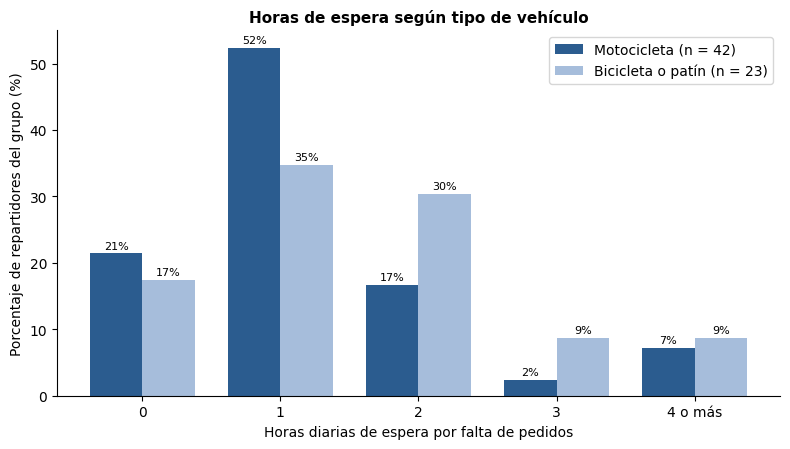

In [78]:
# GRÁFICO H3
COLOR_MOTO, COLOR_BICI = "#2b5c8f", "#a6bddb"

categorias_horas = [0, 1, 2, 3, 4]
etiquetas = ["0", "1", "2", "3", "4 o más"]

def distribucion_pct(serie):
    """Porcentaje de repartidores del grupo por cantidad de horas (4 = 4 horas o más, solo para el gráfico)."""
    horas = serie.clip(upper=4).round().astype(int)
    return horas.value_counts(normalize=True).reindex(categorias_horas, fill_value=0) * 100

pct_moto = distribucion_pct(g_moto)
pct_bici = distribucion_pct(g_bici)

x = np.arange(len(categorias_horas))
ancho = 0.38

fig, ax = plt.subplots(figsize=(8, 4.6))
barras_moto = ax.bar(x - ancho / 2, pct_moto, ancho, color=COLOR_MOTO, label=f"Motocicleta (n = {n_moto})")
barras_bici = ax.bar(x + ancho / 2, pct_bici, ancho, color=COLOR_BICI, label=f"Bicicleta o patín (n = {n_bici})")

for barras in (barras_moto, barras_bici):
    for b in barras:
        if b.get_height() > 0:
            ax.annotate(f"{b.get_height():.0f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                        ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")

ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_xlabel("Horas diarias de espera por falta de pedidos")
ax.set_ylabel("Porcentaje de repartidores del grupo (%)")
ax.set_title("Horas de espera según tipo de vehículo", fontsize=11, fontweight="bold")
ax.legend()

sns.despine()
plt.tight_layout()
plt.show()

Distribución de la proporción de la jornada dedicada a esperar (Y₂) en cada grupo. La caja muestra el 50% central de los datos y la línea negra, la mediana; cada punto es un repartidor.

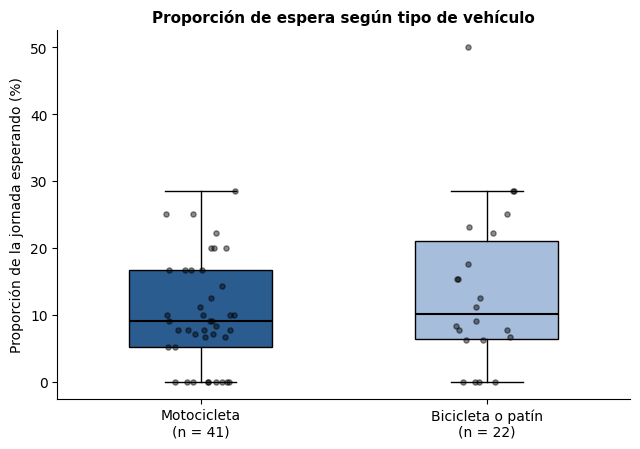

In [79]:
# Colores definidos previamente o configurados por defecto
COLOR_MOTO = "#1f77b4" if 'COLOR_MOTO' not in locals() else COLOR_MOTO
COLOR_BICI = "#ff7f0e" if 'COLOR_BICI' not in locals() else COLOR_BICI

datos_p = [g_moto_p * 100, g_bici_p * 100]

fig, ax = plt.subplots(figsize=(6.5, 4.6))
cajas = ax.boxplot(datos_p, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color="black", linewidth=1.5))
for caja, color in zip(cajas["boxes"], [COLOR_MOTO, COLOR_BICI]):
    caja.set_facecolor(color)

rng_grafico = np.random.default_rng(0)
for i, valores in enumerate(datos_p, start=1):
    ax.scatter(i + rng_grafico.uniform(-0.12, 0.12, len(valores)), valores,
               s=14, color="black", alpha=0.45, zorder=3)

ax.set_xticks([1, 2])
ax.set_xticklabels([f"Motocicleta\n(n = {n_moto_p})", f"Bicicleta o patín\n(n = {n_bici_p})"])
ax.set_ylabel("Proporción de la jornada esperando (%)")
ax.set_title("Proporción de espera según tipo de vehículo", fontsize=11, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()

Estadístico de prueba: Mann-Whitney U, calculado para Y₁ y para Y₂.

In [80]:
estadistico_nombre = "U"

# Y1: horas de espera
res_3 = stats.mannwhitneyu(g_moto, g_bici, alternative="two-sided")
estadistico_3 = res_3.statistic

# Y2: proporción de espera
res_3_p = stats.mannwhitneyu(g_moto_p, g_bici_p, alternative="two-sided")
estadistico_3_p = res_3_p.statistic

print("--- 2. ESTADÍSTICO DE PRUEBA ---")
print(f"Y1 (horas de espera): {estadistico_nombre} = {estadistico_3:.3f}")
print(f"Y2 (proporción de espera): {estadistico_nombre} = {estadistico_3_p:.3f}")

--- 2. ESTADÍSTICO DE PRUEBA ---
Y1 (horas de espera): U = 385.500
Y2 (proporción de espera): U = 388.500


Tamaño del efecto: d de Cohen (0,2 pequeño, 0,5 mediano, 0,8 grande). También se informa la diferencia entre grupos (motocicleta menos bicicleta o patín), en horas para Y₁ y en puntos porcentuales (pp) para Y₂. Como la normalidad no se cumple, el d de Cohen es una aproximación.

In [81]:
# Tamaño del efecto (d de Cohen) para Y1 e Y2
def d_de_cohen(a, b):
    """d de Cohen = (media_a - media_b) / desvío estándar pooled."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    desvio_pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / desvio_pooled

# Y1: horas de espera
d_cohen_h = d_de_cohen(g_moto, g_bici)
dif_medias_h = g_moto.mean() - g_bici.mean()
dif_medianas_h = g_moto.median() - g_bici.median()

# Y2: proporción de espera
d_cohen_p = d_de_cohen(g_moto_p, g_bici_p)
dif_media_p = (g_moto_p.mean() - g_bici_p.mean()) * 100
dif_mediana_p = (g_moto_p.median() - g_bici_p.median()) * 100

print("--- 3b. TAMAÑO DEL EFECTO (d de Cohen) ---")
print("(Referencia: 0,2 pequeño, 0,5 mediano, 0,8 grande; el signo negativo indica que la media de motocicleta es menor)")
print("Y1 (horas de espera):")
print(f"  d de Cohen = {d_cohen_h:.2f}")
print(f"  Diferencia de medias (moto - bici): {dif_medias_h:+.2f} h")
print(f"  Diferencia de medianas (moto - bici): {dif_medianas_h:+.2f} h")
print("\nY2 (proporción de la jornada esperando):")
print(f"  d de Cohen = {d_cohen_p:.2f}")
print(f"  Diferencia de medias (moto - bici): {dif_media_p:+.1f} pp")
print(f"  Diferencia de medianas (moto - bici): {dif_mediana_p:+.1f} pp")
print("(El d de Cohen es aproximado, porque la normalidad no se cumple.)")

--- 3b. TAMAÑO DEL EFECTO (d de Cohen) ---
(Referencia: 0,2 pequeño, 0,5 mediano, 0,8 grande; el signo negativo indica que la media de motocicleta es menor)
Y1 (horas de espera):
  d de Cohen = -0.45
  Diferencia de medias (moto - bici): -0.70 h
  Diferencia de medianas (moto - bici): +0.00 h

Y2 (proporción de la jornada esperando):
  d de Cohen = -0.39
  Diferencia de medias (moto - bici): -3.7 pp
  Diferencia de medianas (moto - bici): -1.0 pp
(El d de Cohen es aproximado, porque la normalidad no se cumple.)


Intervalo de confianza del 95% de la diferencia de medias (fórmula de Welch), para Y₁ y para Y₂. Es aproximado, porque la normalidad no se cumple.

In [82]:
# Intervalo de Confianza 95% de la diferencia de medias (Welch) para Y1 e Y2
def ic_welch(a, b):
    """IC 95% de la diferencia de medias (a - b) con la fórmula de Welch."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    dif = a.mean() - b.mean()
    error_estandar = np.sqrt(va + vb)
    gl = error_estandar ** 4 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    t_critico = stats.t.ppf(1 - ALPHA / 2, gl)
    return dif - t_critico * error_estandar, dif + t_critico * error_estandar

# Y1: horas de espera
ic_inf_3, ic_sup_3 = ic_welch(g_moto, g_bici)

# Y2: proporción de espera, expresada en puntos porcentuales (pp)
ic_inf_3_p, ic_sup_3_p = ic_welch(g_moto_p * 100, g_bici_p * 100)

print("--- 3c. INTERVALO DE CONFIANZA DE WELCH (95%) ---")
print("Y1 (horas de espera):")
print(f"  IC 95% (Welch): [{ic_inf_3:+.2f}; {ic_sup_3:+.2f}] h")
print("\nY2 (proporción de la jornada esperando):")
print(f"  IC 95% (Welch): [{ic_inf_3_p:+.1f}; {ic_sup_3_p:+.1f}] pp")
print("(Los IC son aproximados, porque la normalidad no se cumple.)")

--- 3c. INTERVALO DE CONFIANZA DE WELCH (95%) ---
Y1 (horas de espera):
  IC 95% (Welch): [-1.69; +0.30] h

Y2 (proporción de la jornada esperando):
  IC 95% (Welch): [-9.6; +2.2] pp
(Los IC son aproximados, porque la normalidad no se cumple.)


Potencia: efecto mínimo detectable con 80% de potencia (aproximación normal), según el tamaño de cada grupo. Sirve para saber qué tan grande tendría que ser una diferencia real para que esta muestra pueda detectarla.

In [83]:
d_minimo = (stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(0.80)) * np.sqrt(1 / n_moto + 1 / n_bici)
d_minimo_p = (stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(0.80)) * np.sqrt(1 / n_moto_p + 1 / n_bici_p)   # NUEVO

print("--- 4. POTENCIA DEL ESTUDIO ---")
print(f"Y1: con n = {n_moto} y {n_bici}, y alpha = {ALPHA}, solo se detectan con 80% de potencia efectos de d >= {d_minimo:.2f}.")
print(f"Y2: con n = {n_moto_p} y {n_bici_p}, y alpha = {ALPHA}, solo se detectan con 80% de potencia efectos de d >= {d_minimo_p:.2f}.")

--- 4. POTENCIA DEL ESTUDIO ---
Y1: con n = 42 y 23, y alpha = 0.05, solo se detectan con 80% de potencia efectos de d >= 0.73.
Y2: con n = 41 y 22, y alpha = 0.05, solo se detectan con 80% de potencia efectos de d >= 0.74.


Se compara el p-valor de cada variable con α = 0,05. Si p < α, se rechaza H0. Como se evalúan dos variables dependientes, también se informa qué pasa con la corrección de Bonferroni (α/2 = 0,025).

In [84]:
print("--- 5. CONTRASTE DE HIPÓTESIS Y DECISIÓN ---")

def p_exacto_txt(p):
    """p exacto para informar: 4 decimales si p >= 0,001 y notación científica si es más chico."""
    return f"{p:.4f}".replace(".", ",") if p >= 0.001 else f"{p:.2e}"

p_valor_3 = res_3.pvalue
p_valor_3_p = res_3_p.pvalue
p_exacto_txt_3 = p_exacto_txt(p_valor_3)
p_exacto_txt_3_p = p_exacto_txt(p_valor_3_p)
alpha_bonferroni = ALPHA / 2   # corrección de Bonferroni por evaluar dos variables dependientes

print(f"Nivel de significancia (alpha): {ALPHA}")
print(f"Y1 (horas de espera): {fmt_p(p_valor_3)} (p exacto = {p_exacto_txt_3})")
print(f"Y2 (proporción de espera): {fmt_p(p_valor_3_p)} (p exacto = {p_exacto_txt_3_p})")
print(f"Con la corrección de Bonferroni (alpha / 2 = {alpha_bonferroni:.3f}): "
      f"Y1 {'se rechaza' if p_valor_3 < alpha_bonferroni else 'no se rechaza'} H0; "
      f"Y2 {'se rechaza' if p_valor_3_p < alpha_bonferroni else 'no se rechaza'} H0.")

if p_valor_3 < ALPHA or p_valor_3_p < ALPHA:
    print("-> Se rechaza H0 en al menos una de las dos variables. Como se hicieron 2 pruebas sobre la misma pregunta, "
          "la decisión final se toma con el ajuste de Bonferroni (ver línea anterior).")
else:
    print("-> No se rechaza H0 en ninguna de las dos variables. No se encontró evidencia suficiente de que el tiempo diario de espera "
          "por falta de pedidos, ni la proporción de la jornada dedicada a esperar, difieran entre los repartidores en motocicleta "
          "y en bicicleta o patín.")
    print(f"    Esto no significa que no exista una diferencia: con este tamaño de muestra solo se detectan efectos grandes "
          f"(d >= {d_minimo:.2f} en Y1 y d >= {d_minimo_p:.2f} en Y2).")

--- 5. CONTRASTE DE HIPÓTESIS Y DECISIÓN ---
Nivel de significancia (alpha): 0.05
Y1 (horas de espera): p = 0,157 (p exacto = 0,1569)
Y2 (proporción de espera): p = 0,369 (p exacto = 0,3688)
Con la corrección de Bonferroni (alpha / 2 = 0.025): Y1 no se rechaza H0; Y2 no se rechaza H0.
-> No se rechaza H0 en ninguna de las dos variables. No se encontró evidencia suficiente de que el tiempo diario de espera por falta de pedidos, ni la proporción de la jornada dedicada a esperar, difieran entre los repartidores en motocicleta y en bicicleta o patín.
    Esto no significa que no exista una diferencia: con este tamaño de muestra solo se detectan efectos grandes (d >= 0.73 en Y1 y d >= 0.74 en Y2).


### 7.4. Conclusiones

Robustez de la decisión ante los otros niveles de significancia fijados (α = 0,10 y α = 0,01), para Y₁ y para Y₂.

In [85]:
print("--- ANÁLISIS DE ROBUSTEZ MULTINIVEL (H3) ---")

for nombre, p_val, p_txt in [("Y1 (horas de espera)", p_valor_3, p_exacto_txt_3),
                            ("Y2 (proporción de espera)", p_valor_3_p, p_exacto_txt_3_p)]:
    print(f"\n{nombre} - p exacto: {p_txt}")
    if p_val < ALPHA_ROBUSTO:
        print(f"• Con α = {ALPHA_ROBUSTO} (Robusto): p < α -> Se rechaza H0.")
    else:
        print(f"• Con α = {ALPHA_ROBUSTO} (Robusto): p >= α -> No se rechaza H0 a este nivel.")
    if p_val < ALPHA_LAXO:
        print(f"• Con α = {ALPHA_LAXO} (Laxo): p < α -> Se rechaza H0.")
    else:
        print(f"• Con α = {ALPHA_LAXO} (Laxo): p >= α -> No se rechaza H0 a este nivel.")

--- ANÁLISIS DE ROBUSTEZ MULTINIVEL (H3) ---

Y1 (horas de espera) - p exacto: 0,1569
• Con α = 0.01 (Robusto): p >= α -> No se rechaza H0 a este nivel.
• Con α = 0.1 (Laxo): p >= α -> No se rechaza H0 a este nivel.

Y2 (proporción de espera) - p exacto: 0,3688
• Con α = 0.01 (Robusto): p >= α -> No se rechaza H0 a este nivel.
• Con α = 0.1 (Laxo): p >= α -> No se rechaza H0 a este nivel.


Análisis de sensibilidad (exploratorio): repetimos la comparación sacando el caso que marcó el tope del slider (10 horas) y calculando la proporción de espera con otro denominador (horas de espera / (horas de trabajo + horas de espera)), para ver si el resultado depende de esas decisiones. No reemplaza al análisis principal.

In [86]:
df_h3["prop_trabajo_espera"] = df_h3["horas_espera"] / (df_h3["horas_trabajo"] + df_h3["horas_espera"])

def fila_sensibilidad(nombre, datos, columna):
    a = datos.loc[datos["grupo"] == "Motocicleta", columna].dropna()
    b = datos.loc[datos["grupo"] == "Bicicleta o patín", columna].dropna()
    res = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {"Análisis": nombre, "n moto": len(a), "n bici": len(b),
            "U": round(res.statistic, 1), "p": round(res.pvalue, 3), "d de Cohen": round(d_de_cohen(a, b), 2)}

sin_tope = df_h3[df_h3["horas_espera"] < 10]

tabla_sensibilidad = pd.DataFrame([
    fila_sensibilidad("Y1 horas de espera (análisis principal)", df_h3, "horas_espera"),
    fila_sensibilidad("Y1 horas de espera, sin el caso del tope (10 h)", sin_tope, "horas_espera"),
    fila_sensibilidad("Y2 espera / jornada total (análisis principal)", df_h3, "prop_espera"),
    fila_sensibilidad("Y2 espera / jornada total, sin el caso del tope", sin_tope, "prop_espera"),
    fila_sensibilidad("Y2 alternativa: espera / (trabajo + espera)", df_h3, "prop_trabajo_espera"),
])

print("--- ANÁLISIS DE SENSIBILIDAD (H3) ---")
display(tabla_sensibilidad)
print(f"Casos con más horas de espera que de trabajo: {int((df_h3['horas_espera'] > df_h3['horas_trabajo']).sum())}")

--- ANÁLISIS DE SENSIBILIDAD (H3) ---


,Análisis,n moto,n bici,U,p,d de Cohen
0,Y1 horas de espera (análisis principal),42,23,385.5,0.157,-0.45
1,"Y1 horas de espera, sin el caso del tope (10 h)",42,22,385.5,0.252,-0.29
2,Y2 espera / jornada total (análisis principal),41,22,388.5,0.369,-0.39
3,"Y2 espera / jornada total, sin el caso del tope",41,21,388.5,0.535,-0.24
4,Y2 alternativa: espera / (trabajo + espera),42,23,375.5,0.139,-0.35


Casos con más horas de espera que de trabajo: 1


Conclusión final de la hipótesis 3, que se arma sola con los resultados de la base utilizada.

In [87]:
from IPython.display import Markdown, display

coma = lambda x, f: format(x, f).replace(".", ",")

def decide(p, a):
    return "se rechaza H0" if p < a else "no se rechaza H0"

niveles = (ALPHA, ALPHA_LAXO, ALPHA_ROBUSTO)
misma_decision = len({decide(p, a) for p in (p_valor_3, p_valor_3_p) for a in niveles}) == 1
hay_rechazo = p_valor_3 < ALPHA or p_valor_3_p < ALPHA
hay_rechazo_bonferroni = p_valor_3 < ALPHA / 2 or p_valor_3_p < ALPHA / 2
decision_txt = decide(min(p_valor_3, p_valor_3_p), ALPHA)
decision_txt = decision_txt[0].upper() + decision_txt[1:]
n_tope = int((df_h3["horas_espera"] == 10).sum())

if hay_rechazo:
    resultado_3 = ("la evidencia apoya que el tiempo diario de espera o la proporción de la jornada dedicada a esperar difieren entre "
                   "los repartidores en motocicleta y en bicicleta o patín.")
else:
    resultado_3 = ("no se encontró evidencia suficiente de que el tiempo diario de espera ni la proporción de la jornada dedicada a esperar "
                   "difieran entre los repartidores en motocicleta y en bicicleta o patín.")

display(Markdown(f"""
**Conclusión H3 (α = {coma(ALPHA, '.2f')}).** {decision_txt}: {resultado_3} \
Horas de espera: U = {coma(estadistico_3, '.1f')}, {fmt_p(p_valor_3)}. Proporción de espera: U = {coma(estadistico_3_p, '.1f')}, {fmt_p(p_valor_3_p)}. \
La decisión {"es la misma" if misma_decision else "cambia"} con α = {coma(ALPHA_LAXO, '.2f')} y con α = {coma(ALPHA_ROBUSTO, '.2f')}, \
y {"se rechaza H0 en al menos una variable" if hay_rechazo_bonferroni else "no se rechaza H0 en ninguna variable"} con la corrección de Bonferroni (α/2 = {coma(ALPHA / 2, '.3f')}).

**Tamaño del efecto e incertidumbre.** Horas de espera: d de Cohen = {coma(d_cohen_h, '+.2f')}; medianas de {coma(g_moto.median(), '.2f')} h (motocicleta) y {coma(g_bici.median(), '.2f')} h (bicicleta o patín); IC 95% de la diferencia de medias (Welch, aproximado) [{coma(ic_inf_3, '+.2f')}; {coma(ic_sup_3, '+.2f')}] h. \
Proporción de espera: d de Cohen = {coma(d_cohen_p, '+.2f')}; medianas de {coma(g_moto_p.median() * 100, '.1f')}% (motocicleta) y {coma(g_bici_p.median() * 100, '.1f')}% (bicicleta o patín); IC 95% de la diferencia de medias (Welch, aproximado) [{coma(ic_inf_3_p, '+.1f')}; {coma(ic_sup_3_p, '+.1f')}] pp. \
Con n = {n_moto} y {n_bici}, solo se detectan con 80% de potencia efectos de d >= {coma(d_minimo, '.2f')} (Y1), y con n = {n_moto_p} y {n_bici_p}, de d >= {coma(d_minimo_p, '.2f')} (Y2).

**Limitaciones.** La muestra es chica y no probabilística; el tipo de vehículo se toma de la observación de campo vinculada a cada encuesta; \
hay {n_tope} caso(s) en el tope del slider (10 horas); la jornada total se calcula sumando las horas de trabajo, descanso y espera declaradas, \
suponiendo que no se superponen; el d de Cohen y los IC de Welch son aproximaciones porque no se cumple la normalidad. El diseño es observacional: no permite afirmar causalidad.
"""))


**Conclusión H3 (α = 0,05).** No se rechaza H0: no se encontró evidencia suficiente de que el tiempo diario de espera ni la proporción de la jornada dedicada a esperar difieran entre los repartidores en motocicleta y en bicicleta o patín. Horas de espera: U = 385,5, p = 0,157. Proporción de espera: U = 388,5, p = 0,369. La decisión es la misma con α = 0,10 y con α = 0,01, y no se rechaza H0 en ninguna variable con la corrección de Bonferroni (α/2 = 0,025).

**Tamaño del efecto e incertidumbre.** Horas de espera: d de Cohen = -0,45; medianas de 1,00 h (motocicleta) y 1,00 h (bicicleta o patín); IC 95% de la diferencia de medias (Welch, aproximado) [-1,69; +0,30] h. Proporción de espera: d de Cohen = -0,39; medianas de 9,1% (motocicleta) y 10,1% (bicicleta o patín); IC 95% de la diferencia de medias (Welch, aproximado) [-9,6; +2,2] pp. Con n = 42 y 23, solo se detectan con 80% de potencia efectos de d >= 0,73 (Y1), y con n = 41 y 22, de d >= 0,74 (Y2).

**Limitaciones.** La muestra es chica y no probabilística; el tipo de vehículo se toma de la observación de campo vinculada a cada encuesta; hay 1 caso(s) en el tope del slider (10 horas); la jornada total se calcula sumando las horas de trabajo, descanso y espera declaradas, suponiendo que no se superponen; el d de Cohen y los IC de Welch son aproximaciones porque no se cumple la normalidad. El diseño es observacional: no permite afirmar causalidad.
